# One tile, stage by stage

One 10° × 10° tile of the survey at the true parameters, through every stage of the map-level simulator
and the cluster finder, with the public 2019 SO forecast noise. Runs on a laptop CPU: about 1 min the first
time (the paint tables are built and cached, the code is compiled), a few seconds after; about 3.5 GB of
memory.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
%config InlineBackend.figure_format = "retina"
import jax
jax.config.update("jax_enable_x64", True)
from classy_szlite.sim import tile, priors

t0 = time.time()
o = tile.stages()          # the first tile of the first mock of the published 'truth' set
print(f"{time.time() - t0:.0f} s")

22 s


## The maps

`o` holds the Compton-y map, the 145 GHz map and its three parts, and the finder's signal-to-noise before
and after its masking pass, each 1200 × 1200 pixels of 0.5′.

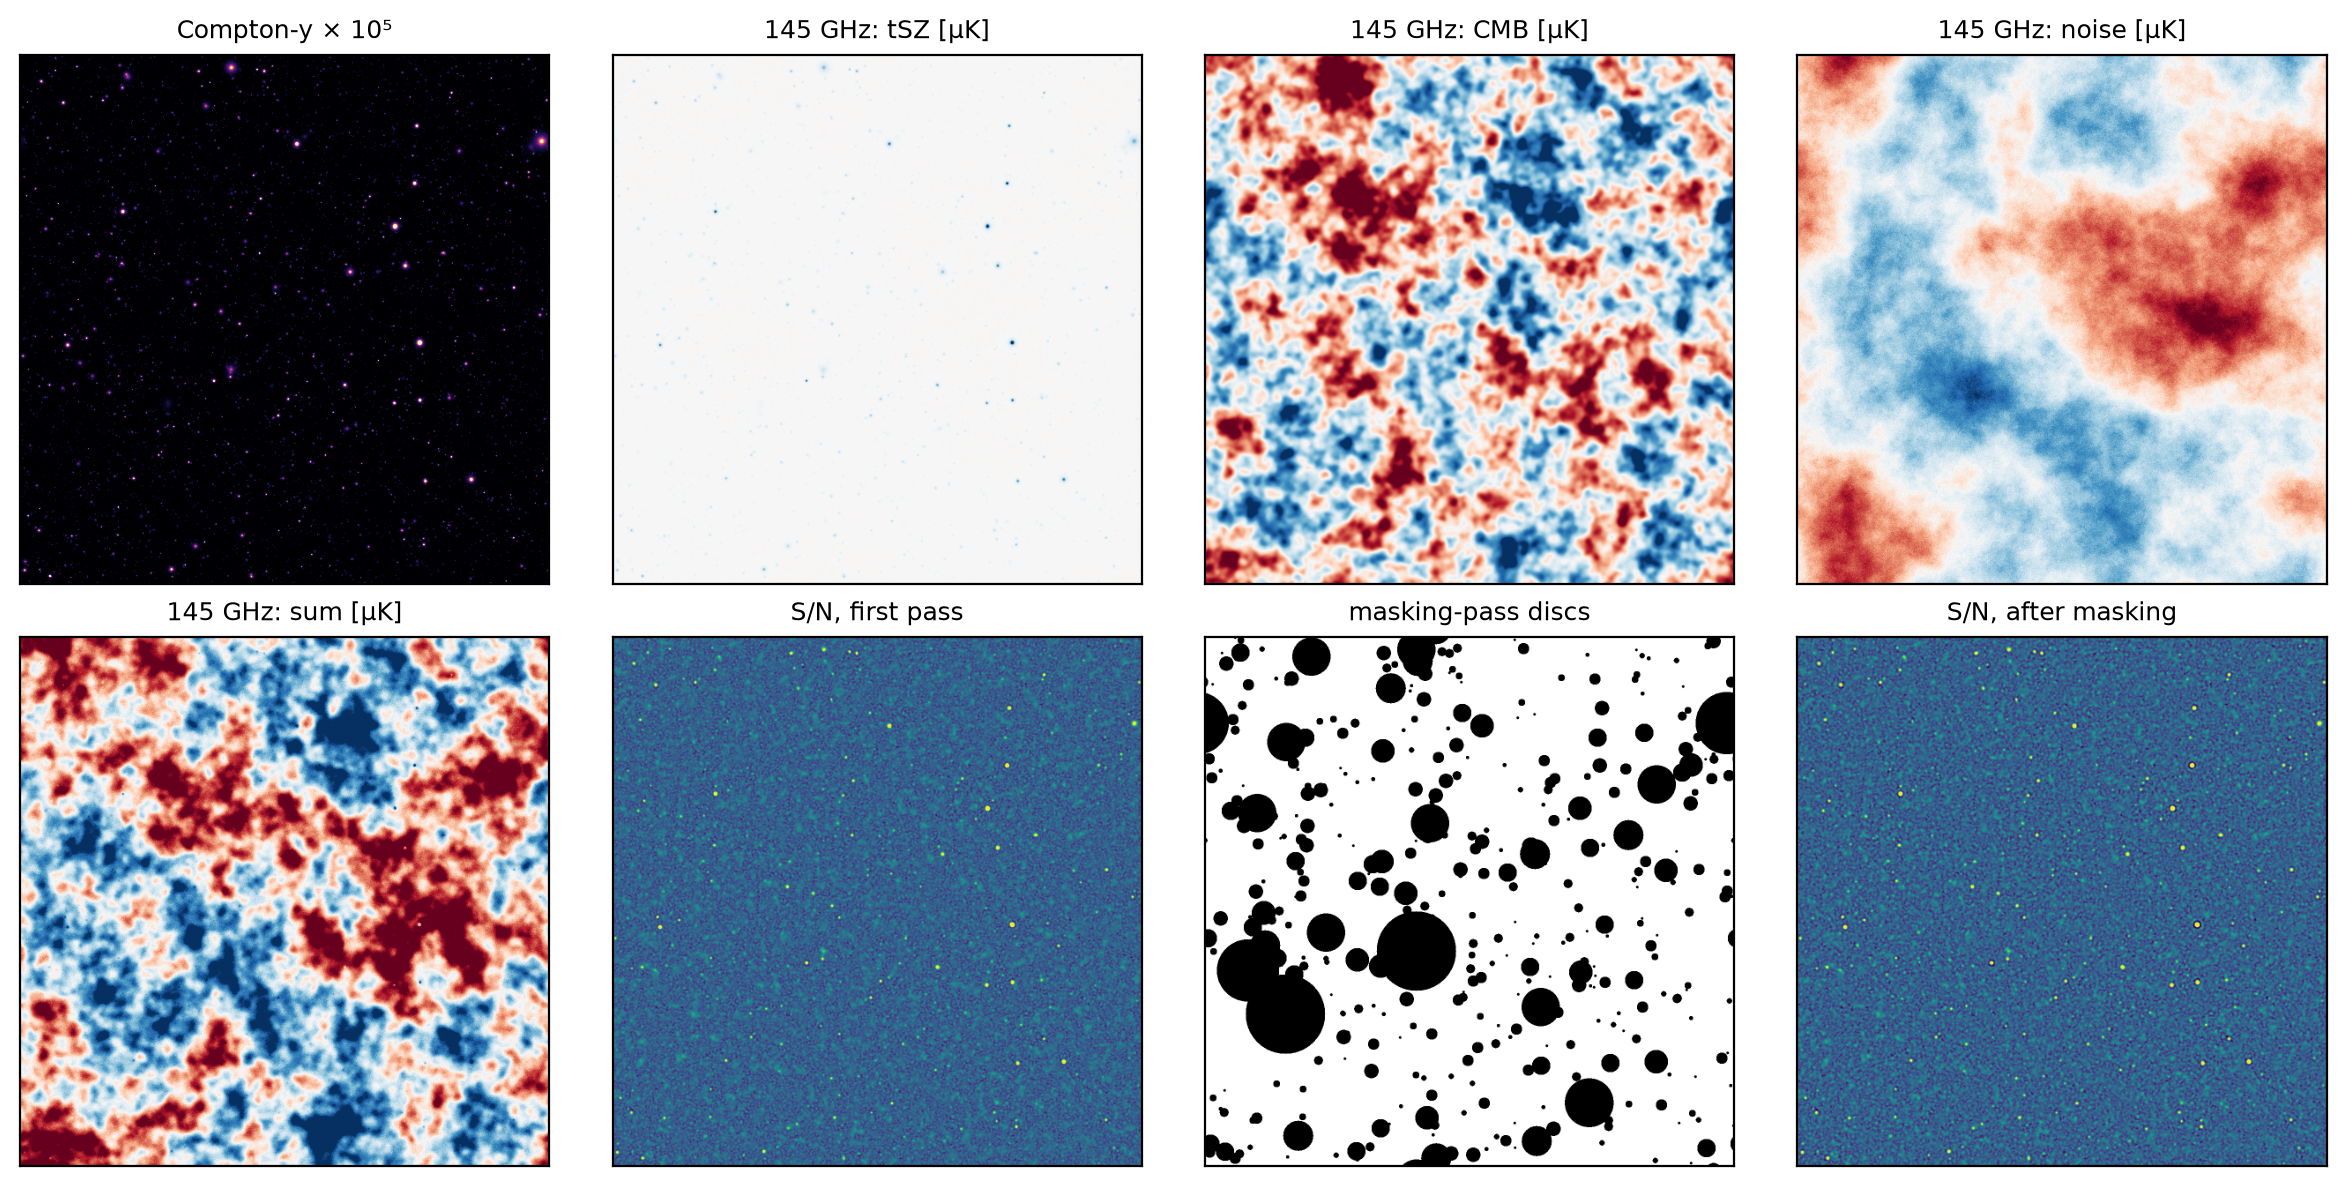

In [2]:
down = lambda a: a.reshape(600, 2, 600, 2).mean((1, 3))
panels = [("y", "Compton-y × 10⁵", "magma", 0, 3), ("tsz145", "145 GHz: tSZ [μK]", "RdBu_r", -200, 200),
          ("cmb145", "145 GHz: CMB [μK]", "RdBu_r", -200, 200), ("noise145", "145 GHz: noise [μK]", "RdBu_r", -200, 200),
          ("m145", "145 GHz: sum [μK]", "RdBu_r", -200, 200), ("q_first", "S/N, first pass", "viridis", -3, 8),
          ("mask", "masking-pass discs", "gray", 0, 1), ("q_final", "S/N, after masking", "viridis", -3, 8)]
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
for a, (k, t, cm, lo, hi) in zip(ax.ravel(), panels):
    m = o[k] * (1e5 if k == "y" else 1)
    a.imshow(down(m), cmap=cm, vmin=lo, vmax=hi, origin="lower", extent=[0, 10, 0, 10])
    a.set_title(t, fontsize=9); a.set_xticks([]); a.set_yticks([])
plt.tight_layout()

The top row splits the 145 GHz map into its parts on a common scale: the clusters' tSZ (a decrement of
up to about 100 μK), the lensed CMB (±200 μK on degree scales) and the forecast noise (its atmospheric part
dominates the largest scales). No cluster is visible in their sum: the finder combines all six channels with
the clusters' known spectrum and shape. Its signal-to-noise before masking is held down by the bright
clusters' own power in the noise estimate; the masking pass covers them (black discs), and the final
signal-to-noise shows the detections as bright points.

## The catalogue

Halos above $5\times10^{13}\,M_\odot$, and the finder's kept peaks with $q > 4$; a peak is confirmed if
a halo above that mass lies within 1.5′.

In [3]:
p, h = o["peaks"], o["halos"]
det = p["confirmed"] & (p["q"] > 5)
print(f"halos above 5e13 Msun: {len(h['z'])}")
print(f"kept peaks with q > 4: {len(p['q'])}; confirmed with q > 5: {det.sum()}; not confirmed with q > 5: {np.sum(~p['confirmed'] & (p['q'] > 5))}")
order = np.argsort(-p["q"])[:8]
print("brightest detections: q, size [arcmin], the halo's z, M500 [Msun] and catalogue-model q")
for i in order:
    j = p["halo"][i]
    print(f"  {p['q'][i]:6.1f}  {p['size'][i]:4.1f}'  " + (f"z {h['z'][j]:.2f}  M {h['M500'][j]:.1e}  q_model {h['q_model'][j]:.1f}" if j >= 0 else "no halo"))

halos above 5e13 Msun: 4292
kept peaks with q > 4: 566; confirmed with q > 5: 324; not confirmed with q > 5: 0
brightest detections: q, size [arcmin], the halo's z, M500 [Msun] and catalogue-model q
    72.5   3.5'  z 0.48  M 1.1e+15  q_model 78.8
    53.4   2.7'  z 0.63  M 6.8e+14  q_model 57.3
    47.0   4.5'  z 0.33  M 8.1e+14  q_model 50.9
    38.6   2.7'  z 0.50  M 6.7e+14  q_model 40.7
    35.2   2.1'  z 0.54  M 6.4e+14  q_model 38.6
    32.0   1.3'  z 1.11  M 5.5e+14  q_model 36.2
    30.4   4.5'  z 0.31  M 7.7e+14  q_model 32.2
    29.8   2.7'  z 0.56  M 6.1e+14  q_model 35.2


The brightest detections all sit on massive halos, and the catalogue model's $q$ of each halo is a few
per cent above the finder's $q$. A detection without a halo is a noise peak or a blend of halos below the
confirmation mass; there are few above $q = 5$.

## The finder's noise

The finder estimates its noise from the maps, which contain the tSZ of every cluster. Before masking, the
bright clusters raise it by 20–30%; after masking, the faint ones still add 4–8% over the instrument and the
CMB: the confusion noise that the catalogue model leaves out.

after masking, at 2':  1.082


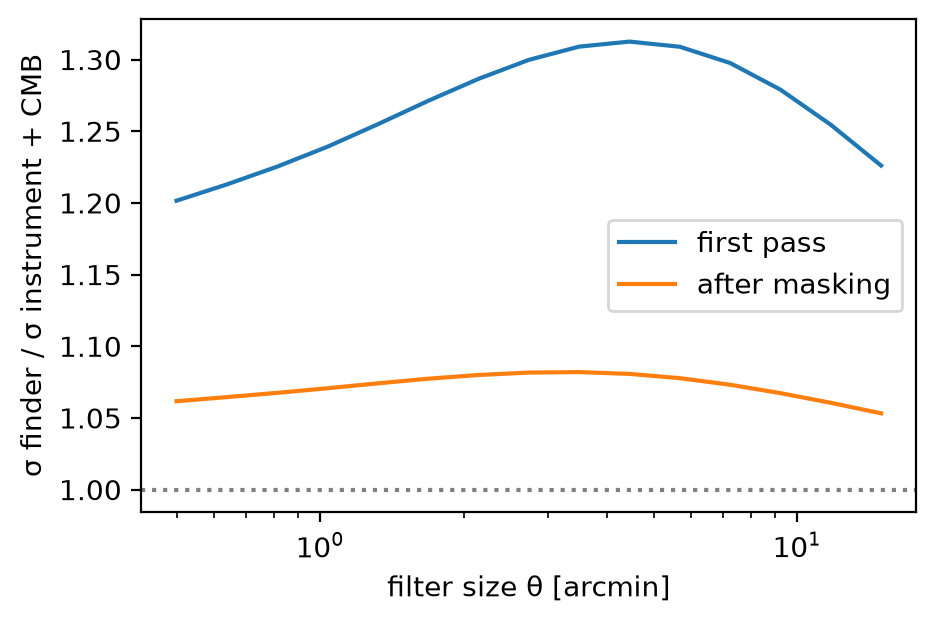

In [4]:
th = o["thetas"]
plt.figure(figsize=(5, 3.2))
plt.plot(th, o["sigma_first"] / o["sigma_model"], label="first pass")
plt.plot(th, o["sigma_final"] / o["sigma_model"], label="after masking")
plt.axhline(1, color="gray", ls=":")
plt.xscale("log"); plt.xlabel("filter size θ [arcmin]"); plt.ylabel("σ finder / σ instrument + CMB"); plt.legend()
print("after masking, at 2': ", round(float(o["sigma_final"][7] / o["sigma_model"][7]), 3))

The first-pass curve peaks on 2–8′ scales, the size of typical clusters, whose power the noise estimate
includes. After masking, the curve drops to 4–8% above 1: the confusion noise of the faint clusters that stay
unmasked. On a single tile the numbers fluctuate by about a per cent from tile to tile.

## Detected q against the catalogue model's q

For every confirmed detection, the finder's $q$ against the catalogue model's $q$ of its halo. Above
$q \approx 6$ the finder's is lower (its noise is higher); near the threshold the search over positions and
sizes lifts it.

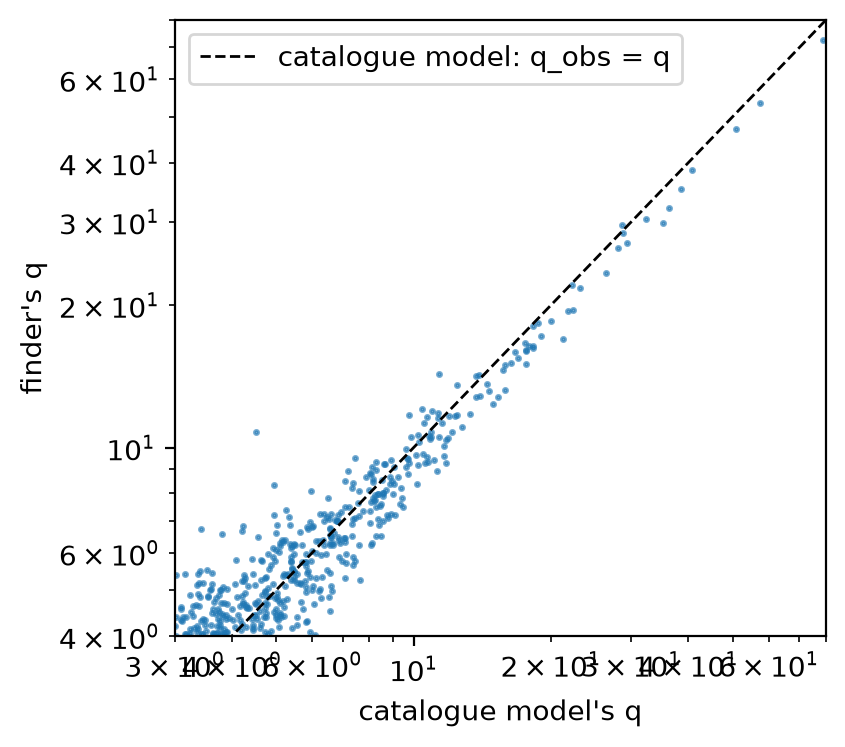

In [5]:
qm = h["q_model"][p["halo"][p["confirmed"]]]
qo = p["q"][p["confirmed"]]
plt.figure(figsize=(4.2, 4))
plt.loglog(qm, qo, ".", ms=3, alpha=0.6)
plt.plot([3, 80], [3, 80], "k--", lw=1, label="catalogue model: q_obs = q")
plt.xlim(3, 80); plt.ylim(4, 80); plt.xlabel("catalogue model's q"); plt.ylabel("finder's q"); plt.legend()

On one tile the trend is noisy, but the bright clusters sit below the dashed line (the finder's higher
noise), while near the threshold detections scatter above it (the search over positions and sizes). The
Finder page measures both effects on 3.6 million halos.